# Smart Nyuki: harvest readiness and yield, v2

**Executed research demonstration. Synthetic data only. No Kenyan field accuracy established.**

Pilot context: **Kiambu, Kajiado, Nakuru and Baringo**, using **Langstroth and Kenya Top Bar** hives.
This notebook replaces simulated days-to-harvest with a clearly defined readiness target and a separate
weighed-yield target. A model can win the benchmark and still fail the recommendation release check.

1. Generate hourly telemetry with separate sugar/water stores, variable weather and flowering scenarios.
2. Construct causal daily features at 18:00 Nairobi time, before manipulation.
3. Attach sparse simulated moisture/capping observations and extraction labels.
4. Compare calibrated XGBoost, CatBoost, LightGBM and simpler baselines.
5. Freeze the candidate/threshold, test future known hives, new hives and new apiaries, and apply advisory checks.

The equations and scenario parameters are illustrative. They are **not calibrated Kenyan bee physiology**.
Public harvest calendars are context, not hive readiness labels. The original v1 notebook is in `backups/`.

## 1. Runtime and portable implementation

CPU is sufficient. The next cell installs dependencies only when required. The collapsed bootstrap contains
the same reviewed implementation as `harvest_readiness.py`, so uploading this notebook alone to Colab works.
An existing different module is never silently overwritten.

In [1]:
import importlib.util, importlib.metadata, subprocess, sys
requirements = ['numpy>=2.0,<3','pandas>=2.2,<4','scikit-learn>=1.5,<2',
    'xgboost>=2.1,<4','catboost>=1.2,<2','lightgbm>=4.5,<5','joblib>=1.4,<2','matplotlib>=3.9,<4']
modules = ['numpy','pandas','sklearn','xgboost','catboost','lightgbm','joblib','matplotlib']
if any(importlib.util.find_spec(name) is None for name in modules):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*requirements])
print('Python:',sys.version.split()[0], '| CPU benchmark | Synthetic demonstration')

Python: 3.12.14 | CPU benchmark | Synthetic demonstration


In [2]:
from pathlib import Path
import hashlib
MODULE_SOURCE = '"""Smart Nyuki v2: causal, inspection-labelled harvest advisory experiments.\n\nSynthetic results are pipeline evidence only. This module does not certify honey\nmoisture or authorize harvesting. See HARVEST_V2_GUIDE.md for data contracts.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import asdict, dataclass\nfrom pathlib import Path\nimport argparse\nimport hashlib\nimport importlib.metadata\nimport json\nimport math\nimport warnings\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom sklearn.dummy import DummyClassifier, DummyRegressor\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (average_precision_score, brier_score_loss,\n                             mean_absolute_error, precision_score, recall_score)\nfrom sklearn.pipeline import make_pipeline\nfrom xgboost import XGBClassifier, XGBRegressor\n\nVERSION = "2.0.0"\nTZ = "Africa/Nairobi"\nSEED = 42\nDECISION_HOUR = 18\n\n\n@dataclass(frozen=True)\nclass Policy:\n    moisture_limit_pct: float = 18.0\n    capping_min: float = 0.80\n    precision_target: float = 0.90\n    min_validation_recommendations: int = 10\n    min_weight_coverage: float = 0.80\n    max_weight_age_h: float = 2.0\n    max_inspection_age_days: int = 14\n    min_harvest_kg: float = 3.0\n    jump_threshold_kg: float = 2.0\n    feeding_review_days: int = 30\n    interval_alpha: float = 0.10\n    min_interval_calibration: int = 10\n\n    def __post_init__(self):\n        if not 0<self.moisture_limit_pct<100 or not 0<=self.capping_min<=1:\n            raise ValueError("Invalid moisture/capping policy")\n        if not 0<self.precision_target<=1 or not 0<self.interval_alpha<1:\n            raise ValueError("Invalid precision/interval probability")\n        if self.min_validation_recommendations<1 or self.min_interval_calibration<1:\n            raise ValueError("Calibration/recommendation counts must be positive")\n\n\n@dataclass(frozen=True)\nclass SplitPlan:\n    train_end: str = "2025-01-01"\n    calibration_end: str = "2025-04-01"\n    validation_end: str = "2025-07-01"\n    # Must be declared before training; names do not encode the target.\n    development_apiaries: tuple = ("apiary_0", "apiary_1", "apiary_2", "apiary_3")\n    heldout_apiaries: tuple = ("apiary_4", "apiary_5")\n    heldout_hives: tuple = tuple(f"apiary_{a}_h{h:02d}" for a in range(4) for h in (3,4))\n\n\ndef local_times(values):\n    """Require explicit time zones; naive field timestamps must be fixed by owner."""\n    s = pd.Series(values)\n    if len(s) == 0 or not s.notna().any():\n        return pd.to_datetime(s, utc=True).dt.tz_convert(TZ)\n    parsed = pd.to_datetime(s)\n    if parsed.dt.tz is None:\n        raise ValueError("Timestamps must include a timezone, e.g. +03:00")\n    return parsed.dt.tz_convert(TZ)\n\n\ndef vpd_kpa(temp_c, rh_pct):\n    """Air VPD, not comb moisture. Invalid sensor values remain missing."""\n    t, rh = np.asarray(temp_c, float), np.asarray(rh_pct, float)\n    valid = (t >= -10) & (t <= 65) & (rh >= 0) & (rh <= 100)\n    return np.where(valid, 0.6108 * np.exp(17.27 * t / (t + 237.3)) * (1 - rh / 100), np.nan)\n\n\n# %% Synthetic hourly telemetry and independent inspection records\ndef simulate(seed=SEED, days=731, hives_per_apiary=5):\n    """Illustrative sugar/water mass balance; NOT a fitted Kenyan bee model.\n\n    Weather/forage profiles vary by apiary and year, flowering responds with\n    variable lags, and drought can interrupt flow. No universal Kenyan harvest\n    month or universal flight cutoff is imposed. Inspections precede extraction.\n    """\n    rng = np.random.default_rng(seed)\n    dates = pd.date_range("2024-01-01", periods=days, tz=TZ)\n    telemetry, inspections = [], []\n    # Illustrative highland/dryland scenarios, not county climate estimates.\n    profiles = [(18, 1.1), (25, .65), (19, .9), (29, .7), (19, 1.2), (28, .55)]\n    counties = ["Kiambu", "Kajiado", "Nakuru", "Baringo", "Kiambu", "Baringo"]\n    for a, (base_t, rain_scale) in enumerate(profiles):\n        apiary = f"apiary_{a}"\n        doy = dates.strftime("%j").astype(int).to_numpy()\n        phase = rng.normal(0, 20)\n        peaks = (np.exp(-.5 * ((doy - (110 + phase)) / 32)**2)\n                 + .7 * np.exp(-.5 * ((doy - (310 + phase)) / 28)**2))\n        wet_year = {y: rng.uniform(.5, 1.4) for y in dates.year.unique()}\n        rain = rng.gamma(.65, 7 * peaks * rain_scale + .25, days)\n        rain *= np.array([wet_year[y] for y in dates.year])\n        lag = int(rng.integers(12, 36))\n        past_rain = pd.Series(rain).rolling(21, min_periods=1).mean().shift(lag).fillna(0)\n        flowering = np.clip(past_rain.to_numpy() / 4, 0, 1.3)\n        # A local flowering pulse and dry interruption deliberately break a\n        # fixed national two-season calendar. Parameters are scenario choices.\n        flowering += .3 * np.exp(-.5 * ((doy - (40 + 13*a)) / 25)**2)\n        drought_start = 170 + 11 * a\n        drought = (np.arange(days) % 365 > drought_start) & (np.arange(days) % 365 < drought_start + 35)\n        flowering[drought] *= .1\n        for h in range(hives_per_apiary):\n            hive = f"{apiary}_h{h:02d}"\n            hive_type = "Langstroth" if h % 2 == 0 else "Kenya_Top_Bar"\n            frame_count = 10 if hive_type == "Langstroth" else 24\n            tare, reserve = rng.uniform(17, 27), rng.uniform(4, 8)\n            strength, ventilation = rng.uniform(.6, 1.2), rng.uniform(.65, 1.4)\n            sugar, water = rng.uniform(4, 7), rng.uniform(.8, 1.5)\n            capped, equipment = .5, 0.0\n            last_harvest = -100\n            inspection_offset = int(rng.integers(0, 7))\n            queen_loss_start = int(rng.integers(100, max(101, days-50)))\n            shade = rng.uniform(.1, .9)\n            for d, day in enumerate(dates):\n                queenright = not (queen_loss_start <= d < queen_loss_start+28)\n                current_strength = strength * (1 if queenright else .65)\n                mean_t = base_t + 2*np.cos(2*np.pi*(doy[d]-50)/365) + rng.normal(0, 1)\n                ext_hum_base = np.clip(45 + 25*min(rain[d]/10, 1) + rng.normal(0, 8), 20, 90)\n                nectar_today = max(0, 1.9 * flowering[d] * current_strength * rng.uniform(.7, 1.3))\n                nectar_today *= np.exp(-rain[d]/22) * np.exp(-max(mean_t-32, 0)/14)\n                sugar_fraction = rng.uniform(.25, .45)\n                harvest_due = 0.0\n                feeding = .7 if sugar+water < reserve*.6 and rng.random() < .25 else 0\n                is_inspection = d % 7 == inspection_offset\n                for hour in range(24):\n                    timestamp = day + pd.Timedelta(hours=hour)\n                    daylight = max(0, np.sin(np.pi*(hour-6)/12))\n                    ext_t = mean_t + 5*np.sin(2*np.pi*(hour-8)/24)\n                    ext_rh = np.clip(ext_hum_base - 12*np.sin(2*np.pi*(hour-8)/24), 15, 98)\n                    int_t = ext_t + (33-ext_t)*(.35+.25*current_strength) - 1.5*shade\n                    int_rh = np.clip(ext_rh*.55 + 29 + 5*flowering[d], 30, 95)\n                    incoming = nectar_today * daylight / 7.595754\n                    sugar += incoming * sugar_fraction\n                    water += incoming * (1-sugar_fraction)\n                    equilibrium_water = sugar * .17/.83\n                    evaporated = max(water-equilibrium_water, 0) * .075 * ventilation * min(float(vpd_kpa(int_t, int_rh))/1.2, 1.8)\n                    water = max(water-evaporated, 0)\n                    consumed = min(sugar+water, (.09+.07*current_strength)/24)\n                    fraction = sugar/max(sugar+water, 1e-9)\n                    sugar = max(0, sugar-consumed*fraction)\n                    water = max(0, water-consumed*(1-fraction))\n                    moisture = 100*water/max(sugar+water, 1e-9)\n                    desired_capping = np.clip((21-moisture)/3.0, 0, 1)\n                    capped += .04 * (desired_capping-capped)\n                    # Inspector samples the designated storage area at 18:00 before manipulation.\n                    if hour == DECISION_HOUR and is_inspection:\n                        surplus = max(sugar+water-reserve, 0)\n                        measured_moisture = np.clip(moisture+rng.normal(0, .25), 10, 70)\n                        measured_capping = np.clip(capped+rng.normal(0, .025), 0, 1)\n                        harvest_due = (surplus*rng.uniform(.82, .94) if\n                            moisture < 18.3 and capped > .75 and surplus > 3\n                            and queenright and d-last_harvest > 28 and rng.random() < .75 else 0)\n                        inspections.append(dict(hive_id=hive, apiary_id=apiary, timestamp=timestamp,\n                            readiness_observed_at=timestamp, yield_observed_at=timestamp+pd.Timedelta(hours=1) if harvest_due else pd.NaT,\n                            moisture_pct=measured_moisture, capping_fraction=measured_capping,\n                            representative_sample=sugar+water>.5, queenright=queenright, disease_flag=False,\n                            swarm_flag=False, reserve_verified=surplus > 3,\n                            recoverable_yield_kg=round(harvest_due, 2) if harvest_due else np.nan,\n                            data_origin="synthetic"))\n                    removed, equip_delta, feed = 0., 0., 0.\n                    if hour == DECISION_HOUR+1 and harvest_due > 0:\n                        removed = min(harvest_due, sugar+water)\n                        f = removed/max(sugar+water, 1e-9)\n                        sugar *= 1-f; water *= 1-f\n                        last_harvest = d\n                        harvest_due = 0\n                    if hour == 12 and feeding:\n                        feed = feeding\n                        sugar += feed*.6; water += feed*.4\n                    if hour == 10 and rng.random() < 1/(365*3):\n                        equip_delta = 3.0 if equipment == 0 else -equipment\n                        equipment += equip_delta\n                    bee_mass = 2.5*current_strength - .35*current_strength*daylight\n                    weight = tare + equipment + sugar+water+bee_mass + rng.normal(0, .035)\n                    if hour == DECISION_HOUR+1 and is_inspection:\n                        weight -= rng.uniform(1.5, 3.0)  # temporary disturbance, not a permanent correction\n                    row = dict(hive_id=hive, apiary_id=apiary, timestamp=timestamp,\n                        weight_kg=weight,\n                        int_temp=np.clip(np.round(int_t+rng.uniform(-2,2)),0,50),\n                        int_hum=np.clip(np.round(int_rh+rng.uniform(-5,5)),20,90),\n                        ext_temp=np.clip(np.round(ext_t+rng.uniform(-2,2)),0,50),\n                        ext_hum=np.clip(np.round(ext_rh+rng.uniform(-5,5)),20,90),\n                        rain_mm=rain[d]/24, wind_ms=max(0, rng.normal(2.2, 1)),\n                        equipment_delta_kg=equip_delta, harvest_mass_removed_kg=removed, feed_kg=feed,\n                        inspection_event=is_inspection and hour in (19, 20, 21),\n                        tare_kg=tare, frame_count=frame_count, shade_fraction=shade, county=counties[a],\n                        sensor_location="honey_storage", hive_type=hive_type, data_origin="synthetic")\n                    for col in ("weight_kg", "int_temp", "int_hum", "ext_temp", "ext_hum"):\n                        if rng.random() < .02: row[col] = np.nan\n                    telemetry.append(row)\n    return pd.DataFrame(telemetry), pd.DataFrame(inspections)\n\n\n# %% Causal telemetry processing; decision at 18:00 EAT, before manipulation\nSENSORS = ["weight_kg", "int_temp", "int_hum", "ext_temp", "ext_hum"]\nEVENTS = ["equipment_delta_kg", "harvest_mass_removed_kg", "feed_kg", "inspection_event"]\nBASE_FEATURES = ["weight_kg", "dw_24h", "night_loss_kg", "day_gain_kg", "int_vpd", "ext_vpd",\n                 "vapor_pressure_gradient", "int_temp_mean", "int_temp_range", "int_hum_mean",\n                 "ext_temp_mean", "ext_hum_mean", "rain_24h", "wind_mean", "weight_coverage",\n                 "climate_coverage", "weight_age_h", "tare_kg", "frame_count", "shade_fraction", "hive_type_ktbh"]\nFEATURES = BASE_FEATURES + [f"{c}_{w}d" for c in ("dw_24h", "night_loss_kg", "int_vpd", "rain_24h") for w in (3, 7, 14, 30)]\nFEATURES += ["night_loss_decay_7d", "weight_slope_7d", "doy_sin", "doy_cos"]\n\n\ndef validate_telemetry(data):\n    required = ["hive_id", "apiary_id", "timestamp", *SENSORS, *EVENTS,\n                "rain_mm", "wind_ms", "tare_kg", "frame_count", "shade_fraction",\n                "hive_type", "sensor_location", "data_origin"]\n    missing = set(required)-set(data)\n    if missing: raise ValueError(f"Telemetry columns missing: {sorted(missing)}")\n    t = data.copy()\n    t["timestamp"] = local_times(t.timestamp).array\n    if t[["hive_id", "apiary_id", "timestamp", "data_origin"]].isna().any().any():\n        raise ValueError("Hive/apiary/time/origin cannot be missing")\n    if t.duplicated(["hive_id", "timestamp"]).any(): raise ValueError("Duplicate hive timestamps")\n    if t.data_origin.nunique() != 1 or not set(t.data_origin) <= {"synthetic", "field"}:\n        raise ValueError("Use exactly one explicit data origin per experiment")\n    if t.groupby("hive_id").apiary_id.nunique().max() != 1:\n        raise ValueError("Hive relocation requires explicit episode IDs")\n    # This first fitted domain is deliberately explicit; other hive designs need\n    # their own metadata, placement contract and held-out validation.\n    if not t.hive_type.isin(["Langstroth", "Kenya_Top_Bar"]).all() or not t.sensor_location.eq("honey_storage").all():\n        raise ValueError("Contract: Langstroth/Kenya_Top_Bar with sensor in designated honey_storage zone")\n    if not t.timestamp.eq(t.timestamp.dt.floor("h")).all():\n        raise ValueError("Provide hourly observations on the hour; aggregate higher-rate input causally first")\n    for col in SENSORS + ["rain_mm", "wind_ms", "tare_kg", "frame_count", "shade_fraction", *EVENTS]:\n        t[col] = pd.to_numeric(t[col], errors="raise")\n        if np.isinf(t[col].to_numpy(float)).any(): raise ValueError(f"Infinite values in {col}")\n    for col in ("int_hum", "ext_hum"):\n        t.loc[~t[col].between(0, 100), col] = np.nan\n    for col in ("int_temp", "ext_temp"):\n        t.loc[~t[col].between(-10, 65), col] = np.nan\n    t.loc[t.weight_kg < 0, "weight_kg"] = np.nan\n    if t[EVENTS].isna().any().any(): raise ValueError("Event logs must be explicit, not unknown/blank")\n    return t.sort_values(["hive_id", "timestamp"]).reset_index(drop=True)\n\n\ndef build_features(telemetry, policy=Policy()):\n    t = validate_telemetry(telemetry)\n    all_days = []\n    for hive, g in t.groupby("hive_id", sort=True):\n        g = g.set_index("timestamp").sort_index()\n        original_end = g.index.max()\n        grid = pd.date_range(g.index.min(), original_end, freq="h", tz=TZ)\n        g = g.reindex(grid)\n        # Metadata carry-forward is causal; missing complete telemetry hours do\n        # not count as sensor readings. Do not silently invent event log entries.\n        g["event_log_missing"] = g[EVENTS].isna().any(axis=1)\n        for c in ("apiary_id", "tare_kg", "frame_count", "shade_fraction", "data_origin", "hive_type"):\n            g[c] = g[c].ffill()\n        corrections = (g.equipment_delta_kg.fillna(0) - g.harvest_mass_removed_kg.fillna(0) + g.feed_kg.fillna(0)).cumsum()\n        g["adjusted_weight"] = g.weight_kg-corrections\n        previous = g.weight_kg.ffill().shift(1)\n        explained = (g[EVENTS].fillna(0).ne(0).any(axis=1))\n        g["unexplained_jump"] = (g.weight_kg-previous).abs().gt(policy.jump_threshold_kg) & ~explained\n        g["known_event"] = explained\n        g["feeding_event"] = g.feed_kg.fillna(0).gt(0)\n        g["int_vpd"] = vpd_kpa(g.int_temp, g.int_hum)\n        g["ext_vpd"] = vpd_kpa(g.ext_temp, g.ext_hum)\n        g["vapor_pressure_gradient"] = (vpd_kpa(g.int_temp, 100-g.int_hum)\n                                           - vpd_kpa(g.ext_temp, 100-g.ext_hum))\n        seen = pd.Series(g.index.where(g.weight_kg.notna()), index=g.index).ffill()\n        g["weight_age_h"] = (pd.Series(g.index, index=g.index)-seen).dt.total_seconds()/3600\n        g["decision_time"] = (g.index-pd.Timedelta(hours=DECISION_HOUR)).ceil("D") + pd.Timedelta(hours=DECISION_HOUR)\n        # Aggregate all days at once; all groups end at their decision time.\n        g[\'weight_valid\'] = g.weight_kg.notna()\n        g[\'climate_valid\'] = g[[\'int_temp\',\'int_hum\',\'ext_temp\',\'ext_hum\']].notna().all(axis=1)\n        gr = g.groupby(\'decision_time\', sort=True)\n        b = gr.agg(apiary_id=(\'apiary_id\',\'last\'), data_origin=(\'data_origin\',\'last\'),\n            int_vpd=(\'int_vpd\',\'mean\'),ext_vpd=(\'ext_vpd\',\'mean\'),\n            vapor_pressure_gradient=(\'vapor_pressure_gradient\',\'mean\'),\n            int_temp_mean=(\'int_temp\',\'mean\'), int_temp_min=(\'int_temp\',\'min\'),int_temp_max=(\'int_temp\',\'max\'),\n            int_hum_mean=(\'int_hum\',\'mean\'),ext_temp_mean=(\'ext_temp\',\'mean\'),ext_hum_mean=(\'ext_hum\',\'mean\'),\n            wind_mean=(\'wind_ms\',\'mean\'),weight_count=(\'weight_valid\',\'sum\'),climate_count=(\'climate_valid\',\'sum\'),\n            event_recent=(\'known_event\',\'any\'),anomaly_recent=(\'unexplained_jump\',\'any\'),\n            feeding_recent=(\'feeding_event\',\'any\'),\n            event_log_missing=(\'event_log_missing\',\'any\'),\n            tare_kg=(\'tare_kg\',\'last\'),frame_count=(\'frame_count\',\'last\'),shade_fraction=(\'shade_fraction\',\'last\'),\n            hive_type=(\'hive_type\',\'last\'))\n        b = b.loc[b.index <= original_end].copy()\n        idx = b.index\n        def weights(index, column=\'adjusted_weight\'):\n            return g[column].reindex(index).to_numpy()\n        b[\'hive_id\'] = hive\n        b[\'timestamp\'] = idx\n        b[\'weight_kg\'] = weights(idx, \'weight_kg\')\n        b[\'adjusted_weight\'] = weights(idx)\n        b[\'dw_24h\'] = weights(idx)-weights(idx-pd.Timedelta(days=1))\n        night_end = (idx-pd.Timedelta(hours=5)).floor(\'D\')+pd.Timedelta(hours=5)\n        b[\'night_loss_kg\'] = weights(night_end-pd.Timedelta(hours=8))-weights(night_end)\n        day_end = (idx-pd.Timedelta(hours=18)).floor(\'D\')+pd.Timedelta(hours=18)\n        b[\'day_gain_kg\'] = weights(day_end)-weights(day_end-pd.Timedelta(hours=12))\n        b[\'int_temp_range\'] = b.pop(\'int_temp_max\')-b.pop(\'int_temp_min\')\n        b[\'weight_coverage\'] = b.pop(\'weight_count\')/24\n        b[\'climate_coverage\'] = b.pop(\'climate_count\')/24\n        b[\'weight_age_h\'] = weights(idx, \'weight_age_h\')\n        b[\'rain_24h\'] = gr.rain_mm.sum(min_count=20).reindex(idx)\n        b[\'hive_type_ktbh\'] = b.pop(\'hive_type\').eq(\'Kenya_Top_Bar\').astype(int)\n        all_days.extend(b.reset_index(drop=True).to_dict(\'records\'))\n    daily = pd.DataFrame(all_days).sort_values(["hive_id", "timestamp"]).reset_index(drop=True)\n    result=[]\n    for _, g in daily.groupby("hive_id", sort=True):\n        g=g.copy()\n        for c in ("dw_24h", "night_loss_kg", "int_vpd", "rain_24h"):\n            for w in (3, 7, 14, 30):\n                g[f"{c}_{w}d"] = g[c].rolling(w, min_periods=max(2, w//2)).mean()\n        g["night_loss_decay_7d"] = g.night_loss_kg.rolling(3, min_periods=2).mean()-g.night_loss_kg.shift(4).rolling(3, min_periods=2).mean()\n        # Endpoint slope; name explicitly denotes average kg/day, not OLS.\n        g["weight_slope_7d"] = (g.adjusted_weight-g.adjusted_weight.shift(7))/7\n        g["history_days"] = np.arange(len(g))+1\n        g["event_recent"] = g.event_recent.rolling(2, min_periods=1).max().astype(bool)\n        g["anomaly_recent"] = g.anomaly_recent.rolling(2, min_periods=1).max().astype(bool)\n        g["event_log_missing"] = g.event_log_missing.rolling(2, min_periods=1).max().astype(bool)\n        g["feeding_recent"] = g.feeding_recent.rolling(policy.feeding_review_days, min_periods=1).max().astype(bool)\n        doy=g.timestamp.dt.strftime("%j").astype(int)\n        g["doy_sin"],g["doy_cos"] = np.sin(2*np.pi*doy/365.25),np.cos(2*np.pi*doy/365.25)\n        result.append(g)\n    return pd.concat(result, ignore_index=True)\n\n\ndef join_inspections(daily, inspections, policy=Policy()):\n    """Labels join only the inspected decision time. Never backfill targets."""\n    i=inspections.copy()\n    required={"hive_id","apiary_id","timestamp","readiness_observed_at","yield_observed_at",\n        "moisture_pct","capping_fraction","representative_sample","queenright","disease_flag",\n        "swarm_flag","reserve_verified","recoverable_yield_kg","data_origin"}\n    if required-set(i): raise ValueError(f"Inspection columns missing: {sorted(required-set(i))}")\n    for c in ("timestamp","readiness_observed_at","yield_observed_at"):\n        i[c]=local_times(i[c]).array\n    if i.duplicated(["hive_id","timestamp"]).any(): raise ValueError("Duplicate inspections")\n    if set(i.data_origin) != set(daily.data_origin): raise ValueError("Inspection/telemetry origin mismatch")\n    if not i.timestamp.eq(i.timestamp.dt.normalize()+pd.Timedelta(hours=DECISION_HOUR)).all():\n        raise ValueError("Inspect at 18:00 decision time for this experiment; do not relabel other hours silently")\n    for c in ("representative_sample","queenright","disease_flag","swarm_flag","reserve_verified"):\n        if not i[c].dropna().isin([True,False,0,1]).all(): raise ValueError(f"{c} must be boolean or missing")\n    if i.readiness_observed_at.lt(i.timestamp).any(): raise ValueError("Label observed before decision")\n    if (i.recoverable_yield_kg.notna() & (i.yield_observed_at.isna() | i.yield_observed_at.lt(i.timestamp))).any():\n        raise ValueError("Harvest yield requires a valid later observation timestamp")\n    if (i.recoverable_yield_kg.dropna()<0).any(): raise ValueError("Yield cannot be negative")\n    i["ready"] = np.nan\n    measured = i.moisture_pct.between(0,100) & i.capping_fraction.between(0,1) & i.representative_sample.eq(True)\n    i.loc[measured,"ready"] = ((i.loc[measured,"moisture_pct"]<=policy.moisture_limit_pct)\n        & (i.loc[measured,"capping_fraction"]>=policy.capping_min)).astype(int)\n    merged=daily.merge(i.drop(columns="data_origin"), on=["hive_id","apiary_id","timestamp"], how="left", validate="one_to_one")\n    # Availability, not just measurement date, governs label eligibility.\n    merged["readiness_label_time"] = merged.readiness_observed_at\n    return merged\n\n\ndef split_masks(data, plan=SplitPlan(), label_time="readiness_label_time"):\n    t=data.timestamp\n    a,b,c=(pd.Timestamp(v,tz=TZ) for v in (plan.train_end,plan.calibration_end,plan.validation_end))\n    if not a<b<c: raise ValueError("Split boundaries must be increasing")\n    if set(plan.development_apiaries)&set(plan.heldout_apiaries): raise ValueError("Overlapping apiary groups")\n    if not set(data.apiary_id) <= set(plan.development_apiaries)|set(plan.heldout_apiaries):\n        raise ValueError("SplitPlan must assign every apiary to development or holdout")\n    dev=data.apiary_id.isin(plan.development_apiaries) & ~data.hive_id.isin(plan.heldout_hives)\n    observed=data[label_time]\n    return {\n        "train": dev & (t<a) & (observed<a),\n        "calibration": dev & (t>=a) & (t<b) & (observed<b),\n        "validation": dev & (t>=b) & (t<c) & (observed<c),\n        "future_known":dev & (t>=c) & observed.notna(),\n        "future_new_hives":data.apiary_id.isin(plan.development_apiaries) & data.hive_id.isin(plan.heldout_hives) & (t>=c) & observed.notna(),\n        "future_new_apiaries":data.apiary_id.isin(plan.heldout_apiaries) & (t>=c) & observed.notna(),\n    }\n\n\n# %% Model candidates, independent probability calibration and policy selection\nclass PlattModel:\n    """Calibration learns on a distinct chronological calibration partition."""\n    def __init__(self, estimator, columns):\n        self.estimator, self.columns = estimator, list(columns)\n\n    @staticmethod\n    def logits(p):\n        p=np.clip(p, 1e-5, 1-1e-5)\n        return np.log(p/(1-p)).reshape(-1,1)\n\n    def fit(self, train, calibration, target="ready"):\n        if train[target].nunique()<2 or calibration[target].nunique()<2:\n            raise ValueError("Both classes are required in training and calibration")\n        self.estimator.fit(train[self.columns], train[target].astype(int))\n        p=self.estimator.predict_proba(calibration[self.columns])[:,1]\n        self.calibrator=LogisticRegression(C=1.0, random_state=SEED).fit(self.logits(p), calibration[target].astype(int))\n        return self\n\n    def predict_proba(self, frame):\n        p=self.estimator.predict_proba(frame[self.columns])[:,1]\n        return self.calibrator.predict_proba(self.logits(p))[:,1]\n\n\ndef classifier_candidates():\n    from sklearn.preprocessing import StandardScaler\n    candidates={\n        "prior_baseline":DummyClassifier(strategy="prior"),\n        "logistic":make_pipeline(SimpleImputer(strategy="median",add_indicator=True), StandardScaler(),\n                                 LogisticRegression(C=.5,max_iter=1500,random_state=SEED)),\n        "xgboost":XGBClassifier(n_estimators=250,max_depth=3,learning_rate=.04,min_child_weight=5,\n            subsample=.85,colsample_bytree=.85,reg_lambda=5,n_jobs=2,random_state=SEED,eval_metric="logloss"),\n    }\n    try:\n        from catboost import CatBoostClassifier\n        candidates["catboost"]=CatBoostClassifier(iterations=250,depth=4,learning_rate=.04,\n            l2_leaf_reg=5,verbose=False,thread_count=2,random_seed=SEED,allow_writing_files=False)\n    except ImportError:\n        warnings.warn("CatBoost unavailable: benchmark will explicitly omit it")\n    try:\n        from lightgbm import LGBMClassifier\n        candidates["lightgbm"]=LGBMClassifier(n_estimators=250,max_depth=4,num_leaves=12,\n            min_child_samples=20,learning_rate=.04,reg_lambda=5,verbosity=-1,n_jobs=2,random_state=SEED)\n    except ImportError:\n        warnings.warn("LightGBM unavailable: benchmark will explicitly omit it")\n    return candidates\n\n\ndef choose_threshold(y, p, policy=Policy()):\n    """Validation policy only. No feasible threshold means no ready advisory."""\n    y=np.asarray(y,int); p=np.asarray(p,float)\n    feasible=[]\n    for threshold in np.unique(np.r_[np.linspace(.4,.99,80),p]):\n        selected=p>=threshold\n        n=int(selected.sum())\n        if n<policy.min_validation_recommendations: continue\n        precision=float(y[selected].mean())\n        if precision>=policy.precision_target:\n            feasible.append((int(y[selected].sum()),precision,float(threshold),n))\n    if not feasible:\n        return {"threshold":1.01,"enabled":False,"validation_recommendations":0,\n                "validation_precision":None,"reason":"No validation threshold meets precision and sample requirements"}\n    tp,precision,threshold,n=max(feasible,key=lambda x:(x[0],x[1],x[2]))\n    return {"threshold":threshold,"enabled":True,"validation_recommendations":n,\n            "validation_precision":precision,"reason":"Empirical validation criterion; not a field guarantee"}\n\n\ndef binary_metrics(y,p,threshold):\n    y=np.asarray(y,int); p=np.asarray(p,float); pred=p>=threshold\n    n_ready=int(pred.sum()); negatives=int((y==0).sum())\n    return dict(n=len(y),positive_rate=float(y.mean()),brier=float(brier_score_loss(y,p)),\n        pr_auc=float(average_precision_score(y,p)) if y.sum() else None,\n        recommendations=n_ready,precision=float(precision_score(y,pred,zero_division=0)) if n_ready else None,\n        recall=float(recall_score(y,pred,zero_division=0)),\n        false_positive_rate=float(((y==0)&pred).sum()/negatives) if negatives else None)\n\n\ndef quality_mask(data, policy=Policy()):\n    return (data.weight_coverage.ge(policy.min_weight_coverage)\n        & data.climate_coverage.ge(policy.min_weight_coverage)\n        & data.weight_age_h.le(policy.max_weight_age_h) & data.weight_kg.notna()\n        & data.history_days.ge(30) & ~data.anomaly_recent & ~data.event_recent & ~data.event_log_missing)\n\n\ndef release_check(test_rows,policy=Policy()):\n    """Pooled success must not hide weak or undersampled hive-type groups."""\n    def meets(group):\n        rows=[r for r in test_rows if r["task"]=="readiness" and r["group"]==group]\n        return len(rows)==3 and all(r["recommendations"]>=policy.min_validation_recommendations\n            and r["precision"] is not None and r["precision"]>=policy.precision_target for r in rows)\n    pooled=meets("all")\n    by_type={name:meets(name) for name in ("Langstroth","Kenya_Top_Bar")}\n    return dict(pooled_precision_passed=pooled,hive_type_release_passed=by_type,\n                holdout_precision_passed=pooled and all(by_type.values()))\n\n\ndef conformal_radius(residuals, alpha=.1):\n    scores=np.asarray(residuals,float)\n    scores=scores[np.isfinite(scores)]\n    if len(scores)==0: raise ValueError("No calibration residuals")\n    rank=math.ceil((len(scores)+1)*(1-alpha))\n    if rank>len(scores): return float("inf")\n    return float(np.sort(scores)[rank-1])\n\n\ndef predict_yield(bundle, data):\n    centre=np.maximum(0,bundle["yield_model"].predict(data[bundle["features"]]))\n    r=bundle["yield_radius_kg"]\n    return centre,np.maximum(0,centre-r),centre+r\n\n\ndef train_experiment(daily, inspections, plan=SplitPlan(), policy=Policy()):\n    data=join_inspections(daily,inspections,policy)\n    masks=split_masks(data,plan)\n    valid=quality_mask(data,policy) & data.ready.notna()\n    parts={k:data.loc[m&valid].copy() for k,m in masks.items()}\n    for name in ("train","calibration","validation"):\n        if len(parts[name])<30 or parts[name].ready.nunique()!=2:\n            raise ValueError(f"Insufficient independently observed readiness labels in {name}: {len(parts[name])}")\n    fitted, rows={},[]\n    for name,est in classifier_candidates().items():\n        model=PlattModel(est,FEATURES).fit(parts["train"],parts["calibration"])\n        p=model.predict_proba(parts["validation"])\n        selection=choose_threshold(parts["validation"].ready,p,policy)\n        metrics=binary_metrics(parts["validation"].ready,p,selection["threshold"])\n        rows.append(dict(model=name,policy_enabled=selection["enabled"],**metrics,threshold=selection["threshold"]))\n        fitted[name]=(model,selection)\n    leaderboard=pd.DataFrame(rows).sort_values(["policy_enabled","brier"],ascending=[False,True]).reset_index(drop=True)\n    champion=leaderboard.iloc[0].model\n    readiness,selected_policy=fitted[champion]\n    # This ablation is development evidence, not extra tuning on the final test.\n    ablations=[]\n    for label,columns in {\n        "full":FEATURES,\n        "without_calendar":[c for c in FEATURES if not c.startswith("doy_")],\n        "without_vapor_features":[c for c in FEATURES if "vpd" not in c and "vapor" not in c],\n        "without_weather":[c for c in FEATURES if not any(x in c for x in ("ext_","rain","wind","vapor"))],\n    }.items():\n        model=PlattModel(classifier_candidates()["xgboost"],columns).fit(parts["train"],parts["calibration"])\n        p=model.predict_proba(parts["validation"])\n        ablations.append(dict(features=label,**binary_metrics(parts["validation"].ready,p,.5)))\n    # Yield labels exist only after a weighed extraction. Do not create zero\n    # targets on unharvested days, or infer yields from readiness labels.\n    ymasks=split_masks(data,plan,label_time="yield_observed_at")\n    yvalid=quality_mask(data,policy)&data.recoverable_yield_kg.notna()\n    yp={k:data.loc[m&yvalid].copy() for k,m in ymasks.items()}\n    for k in ("train","validation"):\n        if len(yp[k])<5: raise ValueError(f"Too few measured yield events in {k}: {len(yp[k])}")\n    yield_candidates={\n        "median_baseline":DummyRegressor(strategy="median"),\n        "random_forest":make_pipeline(SimpleImputer(strategy="median",add_indicator=True),\n            RandomForestRegressor(n_estimators=250,min_samples_leaf=3,n_jobs=2,random_state=SEED)),\n        "xgboost":XGBRegressor(n_estimators=250,max_depth=2,min_child_weight=4,learning_rate=.04,\n            reg_lambda=10,subsample=.85,n_jobs=2,random_state=SEED),\n    }\n    from catboost import CatBoostRegressor\n    from lightgbm import LGBMRegressor\n    yield_candidates["catboost"]=CatBoostRegressor(iterations=250,depth=3,learning_rate=.04,\n        loss_function="MAE",verbose=False,thread_count=2,random_seed=SEED,allow_writing_files=False)\n    yield_candidates["lightgbm"]=LGBMRegressor(n_estimators=200,max_depth=3,num_leaves=7,\n        min_child_samples=8,reg_lambda=5,learning_rate=.04,verbosity=-1,n_jobs=2,random_state=SEED)\n    yield_rows=[]\n    for name,m in yield_candidates.items():\n        m.fit(yp["train"][FEATURES],yp["train"].recoverable_yield_kg)\n        p=np.maximum(0,m.predict(yp["validation"][FEATURES]))\n        yield_rows.append(dict(model=name,n=len(p),mae_kg=float(mean_absolute_error(yp["validation"].recoverable_yield_kg,p))))\n    yield_board=pd.DataFrame(yield_rows).sort_values("mae_kg").reset_index(drop=True)\n    yield_name=yield_board.iloc[0].model\n    yield_model=yield_candidates[yield_name]\n    calibration=yp["calibration"]\n    interval_available=len(calibration)>=policy.min_interval_calibration\n    radius=(conformal_radius(np.abs(calibration.recoverable_yield_kg-\n        np.maximum(0,yield_model.predict(calibration[FEATURES]))),policy.interval_alpha)\n        if interval_available else float("inf"))\n    bundle=dict(version=VERSION,features=list(FEATURES),readiness_model=readiness,\n        readiness_champion=champion,selected_policy=selected_policy,yield_model=yield_model,\n        yield_champion=yield_name,yield_radius_kg=radius,interval_available=interval_available,\n        policy=asdict(policy),split_plan=asdict(plan),data_origin=data.data_origin.iloc[0],\n        field_validated=False,decision_hour_local=DECISION_HOUR,timezone=TZ,\n        training_domains={"hive_types":["Langstroth","Kenya_Top_Bar"],"sensor_location":"honey_storage"},\n        training_feature_bounds={c:(float(parts["train"][c].min()),float(parts["train"][c].max())) for c in FEATURES})\n    # Freeze candidate and threshold before evaluating any final test partition.\n    tests=[]; predictions=[]\n    for split in ("future_known","future_new_hives","future_new_apiaries"):\n        pset=parts[split]\n        if len(pset):\n            prob=readiness.predict_proba(pset)\n            for group,sub in [("all",pset),("Langstroth",pset[pset.hive_type_ktbh==0]),("Kenya_Top_Bar",pset[pset.hive_type_ktbh==1])]:\n                if len(sub):\n                    tests.append(dict(task="readiness",split=split,group=group,apiaries=int(sub.apiary_id.nunique()),\n                        hives=int(sub.hive_id.nunique()),**binary_metrics(sub.ready,readiness.predict_proba(sub),selected_policy["threshold"])))\n            pp=pset[["hive_id","apiary_id","timestamp","ready","hive_type_ktbh"]].copy()\n            pp["probability"]=prob; pp["split"]=split\n            predictions.append(pp)\n        ys=yp[split]\n        if len(ys):\n            p,lo,hi=predict_yield(bundle,ys)\n            tests.append(dict(task="yield",split=split,group="all",n=len(ys),apiaries=int(ys.apiary_id.nunique()),\n                hives=int(ys.hive_id.nunique()),mae_kg=float(mean_absolute_error(ys.recoverable_yield_kg,p)),\n                bias_kg=float(np.mean(p-ys.recoverable_yield_kg)),interval_coverage=float(np.mean((ys.recoverable_yield_kg>=lo)&(ys.recoverable_yield_kg<=hi))) if interval_available else None,\n                interval_mean_width_kg=float(np.mean(hi-lo)) if interval_available else None))\n    counts={k:{"readiness_labels":len(parts[k]),"yield_events":len(yp[k])} for k in parts}\n    release=release_check(tests,policy)\n    bundle.update(release)\n    policy_tests=[]\n    historical_inspections=inspections.copy()\n    historical_inspections["timestamp"]=local_times(historical_inspections.timestamp).array\n    for split in ("future_known","future_new_hives","future_new_apiaries"):\n        ps=parts[split]\n        if ps.empty: continue\n        # Predictive policy evaluation must not use the same inspection that\n        # supplies the test label, even as an authoritative measurement veto.\n        actions=[advise(bundle,r,historical_inspections[historical_inspections.timestamp<r.timestamp],\n            allow_synthetic_demo=bundle["data_origin"]=="synthetic")["action"] for _,r in ps.iterrows()]\n        selected=np.asarray(actions)=="candidate_ready_verify_frames"\n        policy_tests.append(dict(split=split,n=len(ps),candidate_count=int(selected.sum()),\n            candidate_precision=float(ps.loc[selected,"ready"].mean()) if selected.any() else None,\n            inspection_fraction=float(np.mean(np.asarray(actions)=="inspect_hive")),\n            monitor_fraction=float(np.mean(np.asarray(actions)=="wait_and_monitor"))))\n    metadata=dict(version=VERSION,data_origin=bundle["data_origin"],field_validated=False,\n        readiness_champion=champion,yield_champion=yield_name,selected_policy=selected_policy,\n        holdout_precision_passed=bundle["holdout_precision_passed"],\n        pooled_precision_passed=bundle["pooled_precision_passed"],\n        hive_type_release_passed=bundle["hive_type_release_passed"],\n        policy=asdict(policy),split_plan=asdict(plan),sample_counts=counts,\n        interval_calibration_events=len(calibration),interval_available=interval_available,\n        interval_radius_kg=radius if np.isfinite(radius) else None,\n        decision_time="18:00 Africa/Nairobi, pre-extraction",features=FEATURES,\n        source_sha256=hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),\n        simulator_seed=SEED if bundle["data_origin"]=="synthetic" else None,\n        simulated_sensor_profile="DHT11-like: uniform +/-2 C, +/-5 percent RH, rounded; not a calibration certificate" if bundle["data_origin"]=="synthetic" else None,\n        libraries={p:importlib.metadata.version(p) for p in ("numpy","pandas","scikit-learn","xgboost","catboost","lightgbm")},\n        limitations=["Synthetic mechanism, no field accuracy established" if bundle["data_origin"]=="synthetic" else "Local field performance still requires independent validation",\n          "Field validation requires representative local moisture, inspection and weighed extraction records",\n          "Intervals rely on calibration residual transfer; check coverage under shift",\n          "No trained fanning/absconding detector; colony checks use logged inspections",\n          "Six apiaries and correlated hive-days are not independent field replication",\n          "Readiness label is the configured conservative moisture-plus-capping policy",\n          "Do not use this model to authorize a real harvest"])\n    return bundle,dict(readiness_leaderboard=leaderboard,yield_leaderboard=yield_board,\n        ablations=pd.DataFrame(ablations),test_metrics=pd.DataFrame(tests),metadata=metadata,\n        policy_metrics=pd.DataFrame(policy_tests),\n        test_predictions=pd.concat(predictions,ignore_index=True) if predictions else pd.DataFrame())\n\n\n# %% Advisory: uncertainty, quality, health and reserves can suppress readiness\ndef advise(bundle, row, inspections, allow_synthetic_demo=False):\n    if bundle["data_origin"]=="synthetic" and not allow_synthetic_demo:\n        raise ValueError("Synthetic model is demonstration-only; explicitly opt into demo mode")\n    if row["data_origin"]!=bundle["data_origin"]:\n        raise ValueError("Cannot apply a synthetic model to field telemetry, or mix data origins")\n    policy=Policy(**bundle["policy"])\n    frame=pd.DataFrame([row])\n    p=float(bundle["readiness_model"].predict_proba(frame)[0])\n    centre,lo,hi=predict_yield(bundle,frame)\n    reasons=[]\n    if not bundle.get("holdout_precision_passed",False):\n        reasons.append("Held-out tests lack required precision or sample counts overall or within a hive type")\n    if not quality_mask(frame,policy).iloc[0]: reasons.append("Telemetry incomplete, stale, disturbed, or history shorter than 30 days")\n    if row.get("feeding_recent",True): reasons.append("Recent or unknown feeding history: inspect crop provenance before extraction")\n    i=inspections[inspections.hive_id==row["hive_id"]].copy()\n    if len(i):\n        i["timestamp"]=local_times(i.timestamp).array\n        i["readiness_observed_at"]=local_times(i.readiness_observed_at).array\n        # Health/reserve findings are available when the inspection record is\n        # available; do not use a later-entered record to decide in the past.\n        i=i[(i.timestamp<=row["timestamp"]) & (i.readiness_observed_at<=row["timestamp"])].sort_values("timestamp")\n    if i.empty:\n        reasons.append("No available colony-health/reserve inspection")\n    else:\n        latest=i.iloc[-1]\n        age=(row["timestamp"]-latest.timestamp).total_seconds()/86400\n        if age>policy.max_inspection_age_days: reasons.append("Colony-health/reserve inspection is stale")\n        if pd.isna(latest.queenright) or latest.queenright!=True:\n            reasons.append("Queen status unknown or queenless")\n        for col in ("disease_flag","swarm_flag"):\n            if pd.isna(latest[col]) or latest[col]!=False: reasons.append(f"Health check requires attention: {col}")\n        if pd.isna(latest.reserve_verified) or latest.reserve_verified!=True: reasons.append("Adequate colony reserves not verified")\n        representative=latest.get("representative_sample",False)\n        if latest.timestamp==row["timestamp"] and pd.notna(representative) and representative==True:\n            if pd.notna(latest.get("moisture_pct")) and latest.moisture_pct>policy.moisture_limit_pct:\n                reasons.append("Current measured moisture exceeds project policy; model score cannot override it")\n            if pd.notna(latest.get("capping_fraction")) and latest.capping_fraction<policy.capping_min:\n                reasons.append("Current measured capping is below project policy; model score cannot override it")\n    if not bundle["interval_available"]: reasons.append("Too few independent yield-calibration events")\n    # Simple conservative range monitor. It is not a proven distribution-shift detector.\n    out_of_range=[]\n    for c in ("weight_kg","int_temp_mean","int_hum_mean","ext_temp_mean","ext_hum_mean","tare_kg","frame_count"):\n        low,high=bundle["training_feature_bounds"][c]\n        value=row[c]\n        tolerance=max((high-low)*.15,.5)\n        if pd.notna(value) and (value<low-tolerance or value>high+tolerance): out_of_range.append(c)\n    if out_of_range: reasons.append("Outside fitted feature ranges: "+", ".join(out_of_range))\n    if reasons:\n        action="inspect_hive"\n    elif not bundle["selected_policy"]["enabled"]:\n        action="inspect_hive"; reasons.append("Validation did not support a recommendation threshold")\n    elif p>=bundle["selected_policy"]["threshold"]:\n        if lo[0]>=policy.min_harvest_kg:\n            action="candidate_ready_verify_frames"\n        else:\n            action="inspect_hive"; reasons.append("Yield lower bound does not support the minimum harvest quantity")\n    elif p<.35:\n        action="wait_and_monitor"\n    else:\n        action="inspect_hive"; reasons.append("Readiness probability is inconclusive")\n    return dict(hive_id=row["hive_id"],timestamp=str(row["timestamp"]),action=action,\n        probability_ready=p,yield_kg=float(centre[0]),yield_interval_kg=[float(lo[0]),float(hi[0])] if bundle["interval_available"] else None,\n        reasons=reasons,data_origin=bundle["data_origin"],field_validated=bundle["field_validated"],\n        demonstration_only=bundle["data_origin"]=="synthetic",harvest_authorized=False,\n        holdout_precision_passed=bundle.get("holdout_precision_passed",False))\n\n\ndef save_results(bundle,results,output):\n    output=Path(output); output.mkdir(parents=True,exist_ok=True)\n    joblib.dump(bundle,output/"harvest_readiness_v2.joblib")\n    for name,value in results.items():\n        if isinstance(value,pd.DataFrame): value.to_csv(output/f"{name}.csv",index=False)\n    (output/"model_card.json").write_text(json.dumps(results["metadata"],indent=2,allow_nan=False)+"\\n")\n    return output\n\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--output",default="outputs/harvest_v2")\n    parser.add_argument("--telemetry",help="Field hourly CSV; requires --inspections")\n    parser.add_argument("--inspections",help="Actual field labels CSV")\n    parser.add_argument("--split-config",help="JSON SplitPlan using actual apiary IDs, held-out hives and date boundaries")\n    args=parser.parse_args()\n    if bool(args.telemetry)!=bool(args.inspections): parser.error("Supply both --telemetry and --inspections")\n    plan=SplitPlan()\n    if args.telemetry:\n        telemetry,inspections=pd.read_csv(args.telemetry),pd.read_csv(args.inspections)\n        if not telemetry.data_origin.eq("field").all(): raise ValueError("Field files must declare data_origin=field")\n        if not args.split_config: parser.error("Field training requires --split-config; no synthetic apiary/date defaults")\n        config=json.loads(Path(args.split_config).read_text())\n        for k in ("development_apiaries","heldout_apiaries","heldout_hives"):\n            if k not in config: parser.error(f"Split configuration must declare {k}")\n            config[k]=tuple(config[k])\n        plan=SplitPlan(**config)\n    else:\n        print("DEMONSTRATION ONLY: generating synthetic telemetry",flush=True)\n        telemetry,inspections=simulate()\n    output=Path(args.output); output.mkdir(parents=True,exist_ok=True)\n    origin=telemetry.data_origin.iloc[0]\n    telemetry.to_csv(output/f"{origin}_hourly_telemetry.csv.gz",index=False,compression="gzip")\n    inspections.to_csv(output/f"{origin}_inspections.csv",index=False)\n    print(f"{len(telemetry):,} hourly rows, {len(inspections):,} inspections",flush=True)\n    daily=build_features(telemetry)\n    daily.to_csv(output/"daily_features.csv.gz",index=False,compression="gzip")\n    print("Training development candidates; final tests remain separate",flush=True)\n    bundle,results=train_experiment(daily,inspections,plan=plan)\n    save_results(bundle,results,output)\n    sample_hive=daily.hive_id.iloc[-1]\n    row=daily[daily.hive_id==sample_hive].iloc[-1]\n    advisory=advise(bundle,row,inspections,allow_synthetic_demo=origin=="synthetic")\n    (output/"example_advisory.json").write_text(json.dumps(advisory,indent=2,allow_nan=False)+"\\n")\n    print(results["readiness_leaderboard"].to_string(index=False))\n    print(results["test_metrics"].to_string(index=False))\n    print(json.dumps(advisory,indent=2))\n\n\nif __name__=="__main__":\n    main()\n'
EXPECTED_SHA256 = 'e1ac54bcc3f69a024d000b2eab9c4f4cf21968472f0a6a3f1f31671318af6acb'
module_path = Path('harvest_readiness.py')
if module_path.exists():
    if hashlib.sha256(module_path.read_bytes()).hexdigest() != EXPECTED_SHA256:
        raise RuntimeError('Module differs from this notebook. Regenerate the notebook from the updated module.')
else:
    module_path.write_text(MODULE_SOURCE)
import harvest_readiness as h
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print('Implementation:',h.VERSION,'| SHA256:',EXPECTED_SHA256[:16])

Implementation: 2.0.0 | SHA256: e1ac54bcc3f69a02


## 2. Data provenance and scenarios

The default demonstration uses 30 hives in six illustrative apiaries over two years. County names are
context tags; the generated temperatures, rainfall, stores and inspections are not observations from those counties.
Both supported hive types occur in development and entirely held-out apiaries. Comb rebuilding differences are not fully simulated.

The simulator includes forager mass changes, consumption, water evaporation, varying flowering lags,
dry interruptions, queen-loss episodes, disturbances, feeding, equipment changes and sensor dropouts.
It contains no validated fanning or absconding detector.

Actual field data require a separate declared split plan; set `MODE='field'` only with real records.

In [3]:
MODE = 'synthetic'
OUT = Path('outputs/harvest_v2')
OUT.mkdir(parents=True, exist_ok=True)
plan, policy = h.SplitPlan(), h.Policy()
if MODE == 'synthetic':
    telemetry_file = OUT/'synthetic_hourly_telemetry.csv.gz'
    inspection_file = OUT/'synthetic_inspections.csv'
    if telemetry_file.exists() and inspection_file.exists():
        telemetry, inspections = pd.read_csv(telemetry_file), pd.read_csv(inspection_file)
        assert 'harvest_mass_removed_kg' in telemetry, 'Old cache: remove it and regenerate the hourly demo'
    else:
        telemetry, inspections = h.simulate()
        telemetry.to_csv(telemetry_file,index=False,compression='gzip')
        inspections.to_csv(inspection_file,index=False)
    assert telemetry.data_origin.eq('synthetic').all()
else:
    import json
    telemetry = pd.read_csv('your_hourly_telemetry.csv')
    inspections = pd.read_csv('your_inspections.csv')
    cfg = json.loads(Path('your_split_plan.json').read_text())
    for key in ('development_apiaries','heldout_apiaries','heldout_hives'): cfg[key] = tuple(cfg[key])
    plan = h.SplitPlan(**cfg)
    assert telemetry.data_origin.eq('field').all()
print(f'{len(telemetry):,} hourly rows | {telemetry.hive_id.nunique()} hives | {len(inspections):,} inspections')
display(telemetry.groupby(['apiary_id','hive_type']).size().unstack(fill_value=0))
print('Actual weighed extraction labels:', inspections.recoverable_yield_kg.notna().sum())

526,320 hourly rows | 30 hives | 3,134 inspections


hive_type,Kenya_Top_Bar,Langstroth
apiary_id,,
apiary_0,35088,52632
apiary_1,35088,52632
apiary_2,35088,52632
apiary_3,35088,52632
apiary_4,35088,52632
apiary_5,35088,52632


Actual weighed extraction labels: 235


## 3. Causal features and leakage check

`dw_24h` uses matching clock times on adjacent days. Night loss spans the most recent completed
21:00–05:00 interval. VPD describes air conditions, not measured honey moisture. Missing readings remain
missing, and observation age/coverage are features and gates. Known equipment, harvested mass and feed
are corrected separately; unexplained jumps are preserved as anomalies.

The executable check below verifies that changing later readings cannot change earlier features.

In [4]:
daily = h.build_features(telemetry,policy)
daily.to_csv(OUT/'daily_features.csv.gz',index=False,compression='gzip')
example_hive = telemetry.hive_id.iloc[0]
probe = telemetry[telemetry.hive_id==example_hive].copy()
probe['timestamp'] = h.local_times(probe.timestamp).array
cut = probe.timestamp.min()+pd.Timedelta(days=45,hours=18)
prefix = h.build_features(probe[probe.timestamp<=cut],policy)
changed = probe.copy()
changed.loc[changed.timestamp>cut,h.SENSORS] = 999
recomputed = h.build_features(changed,policy)
pd.testing.assert_frame_equal(prefix,recomputed[recomputed.timestamp<=cut].reset_index(drop=True))
print('PASS: future-only changes do not alter past features')
display(daily[['hive_id','timestamp','dw_24h','night_loss_kg','int_vpd','weight_coverage']].tail())

PASS: future-only changes do not alter past features


,hive_id,timestamp,dw_24h,night_loss_kg,int_vpd,weight_coverage
21925,apiary_5_h04,2025-12-27 18:00:00+03:00,-0.055141,0.076946,2.167358,1.000000
21926,apiary_5_h04,2025-12-28 18:00:00+03:00,-0.005219,NaN,2.161083,0.916667
21927,apiary_5_h04,2025-12-29 18:00:00+03:00,-0.077547,0.041060,1.882439,0.916667
21928,apiary_5_h04,2025-12-30 18:00:00+03:00,0.013618,-0.028182,1.959967,1.000000
21929,apiary_5_h04,2025-12-31 18:00:00+03:00,-0.131046,0.076072,2.350858,1.000000


## 4. Labels and predeclared partitions

The project policy labels an inspected storage area ready when measured moisture is at most 18% **and**
capping is at least 80%. These configurable conservative criteria are not universal biological or legal thresholds.
Uninspected days stay unknown. Only weighed extractions supply yield labels; no extraction means unknown yield.
The inspection measurements themselves are excluded from model inputs.

Development: 2024 training, January–March 2025 calibration, April–June 2025 model/threshold selection.
Tests: July–December 2025, separately for known hives, unseen hives of both types, and wholly unseen apiaries.
Delayed outcomes must be available before their partition cutoff.

In [5]:
labelled = h.join_inspections(daily,inspections,policy)
masks = h.split_masks(labelled,plan)
display(pd.DataFrame([{'partition':k,'labelled_rows':int((v & labelled.ready.notna()).sum()),
    'hives':labelled.loc[v,'hive_id'].nunique()} for k,v in masks.items()]))
print('Unknown readiness days:',labelled.ready.isna().sum())
assert not set(h.FEATURES)&{'ready','moisture_pct','capping_fraction','recoverable_yield_kg'}

,partition,labelled_rows,hives
0,train,629,12
1,calibration,152,12
2,validation,156,12
3,future_known,318,12
4,future_new_hives,210,8
5,future_new_apiaries,262,10


Unknown readiness days: 18799


## 5. Train, calibrate and select

Each classifier fits the training partition and learns a Platt probability calibration on the calibration partition.
Threshold selection uses only the development validation period, requires at least ten recommendations and
empirical precision of at least 90%, and can disable recommendations when no threshold qualifies.
Among feasible candidates, lower Brier score wins. Baselines use training labels only.

Yield model selection uses validation MAE. A separate calibration set supplies an absolute-residual interval.
All estimators use fixed, modest configurations rather than tuning repeatedly against the final tests.

In [6]:
bundle, results = h.train_experiment(daily,inspections,plan,policy)
h.save_results(bundle,results,OUT)
display(results['readiness_leaderboard'].round(4))
display(results['yield_leaderboard'].round(3))
print('Selected readiness:',bundle['readiness_champion'],'| Selected yield:',bundle['yield_champion'])
print('Yield interval radius:',round(bundle['yield_radius_kg'],2),'kg')

,model,policy_enabled,n,positive_rate,brier,pr_auc,recommendations,precision,recall,false_positive_rate,threshold
0,logistic,True,149,0.3221,0.1159,0.8262,11,1.0000,0.2292,0.0000,0.8637
1,catboost,True,149,0.3221,0.1191,0.8582,31,0.9032,0.5833,0.0297,0.5232
2,xgboost,True,149,0.3221,0.1240,0.8355,29,0.9310,0.5625,0.0198,0.5572
3,lightgbm,True,149,0.3221,0.1251,0.8342,30,0.9000,0.5625,0.0297,0.5123
4,prior_baseline,False,149,0.3221,0.2238,0.3221,0,NaN,0.0000,0.0000,1.0100


,model,n,mae_kg
0,xgboost,19,4.705
1,random_forest,19,4.856
2,lightgbm,19,5.768
3,catboost,19,5.872
4,median_baseline,19,10.111


Selected readiness: logistic | Selected yield: xgboost
Yield interval radius: 3.63 kg


## 6. Held-out evidence and release check

Read the final test precision, recall, sample count and interval coverage together. A good ranking score
does not prove that recommendations are safe or well calibrated. The release check requires the configured
precision target and adequate recommendation counts in every overall and hive-type test partition.

Two held-out apiaries and correlated hive-days are limited evidence even in simulation. Synthetic results
cannot establish Kenyan field performance. The export always records `field_validated=False`.

In [7]:
display(results['test_metrics'].round(4))
display(results['policy_metrics'].round(4))
print('Held-out precision criterion passed:',bundle['holdout_precision_passed'])
print('Field validated:',bundle['field_validated'])

,task,split,group,apiaries,hives,n,positive_rate,brier,pr_auc,recommendations,precision,recall,false_positive_rate,mae_kg,bias_kg,interval_coverage,interval_mean_width_kg
0,readiness,future_known,all,4,12,269,0.4461,0.1127,0.8939,26.0,0.9615,0.2083,0.0067,NaN,NaN,NaN,NaN
1,readiness,future_known,Langstroth,4,8,181,0.4365,0.1073,0.9058,25.0,0.9600,0.3038,0.0098,NaN,NaN,NaN,NaN
2,readiness,future_known,Kenya_Top_Bar,4,4,88,0.4659,0.1238,0.8742,1.0,1.0000,0.0244,0.0000,NaN,NaN,NaN,NaN
3,yield,future_known,all,3,9,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.2496,-0.6753,0.8182,7.2608
4,readiness,future_new_hives,all,4,8,171,0.4503,0.1070,0.9085,21.0,0.9524,0.2597,0.0106,NaN,NaN,NaN,NaN
5,readiness,future_new_hives,Langstroth,4,4,79,0.4177,0.0908,0.9135,15.0,0.9333,0.4242,0.0217,NaN,NaN,NaN,NaN
6,readiness,future_new_hives,Kenya_Top_Bar,4,4,92,0.4783,0.1210,0.9268,6.0,1.0000,0.1364,0.0000,NaN,NaN,NaN,NaN
7,yield,future_new_hives,all,4,8,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.6376,-0.0125,1.0000,7.2608
8,readiness,future_new_apiaries,all,2,10,225,0.4533,0.0960,0.8884,21.0,0.9048,0.1863,0.0163,NaN,NaN,NaN,NaN
9,readiness,future_new_apiaries,Langstroth,2,6,130,0.4308,0.1069,0.8468,13.0,0.8462,0.1964,0.0270,NaN,NaN,NaN,NaN


,split,n,candidate_count,candidate_precision,inspection_fraction,monitor_fraction
0,future_known,269,0,None,1.0,0.0
1,future_new_hives,171,0,None,1.0,0.0
2,future_new_apiaries,225,0,None,1.0,0.0


Held-out precision criterion passed: False
Field validated: False


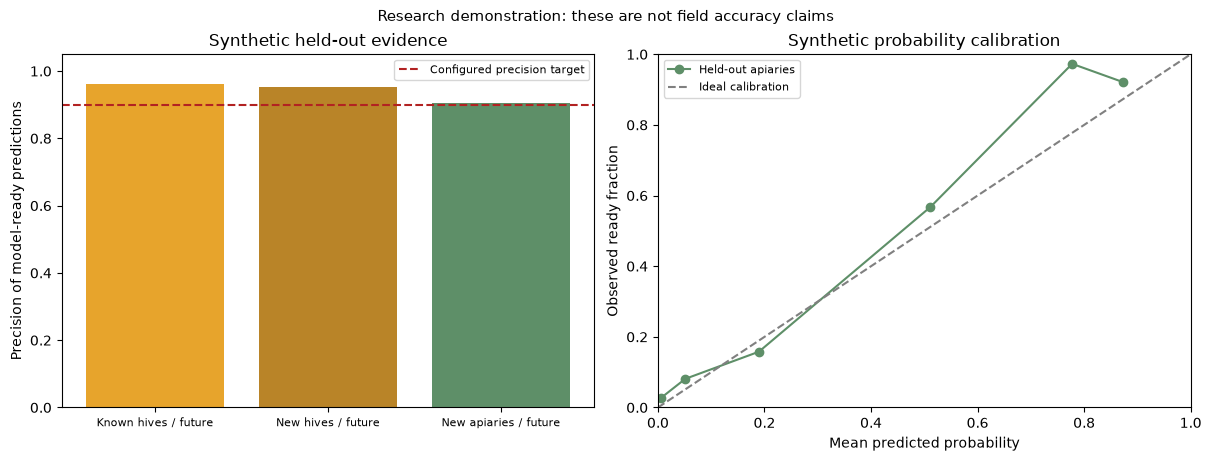

In [8]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
metrics=results['test_metrics']
r=metrics[(metrics.task=='readiness') & (metrics.group=='all')]
names={'future_known':'Known hives / future','future_new_hives':'New hives / future','future_new_apiaries':'New apiaries / future'}
axes[0].bar([names[x] for x in r.split],r.precision,color=['#e7a42c','#b98428','#5e8f68'])
axes[0].axhline(policy.precision_target,color='firebrick',ls='--',label='Configured precision target')
axes[0].set(ylim=(0,1.05),ylabel='Precision of model-ready predictions',title='Synthetic held-out evidence')
axes[0].tick_params(axis='x',labelsize=8)
axes[0].legend(fontsize=8)
pp=results['test_predictions']
pp=pp[pp.split=='future_new_apiaries']
if len(pp):
    observed,predicted=calibration_curve(pp.ready,pp.probability,n_bins=6,strategy='quantile')
    axes[1].plot(predicted,observed,'o-',color='#5e8f68',label='Held-out apiaries')
axes[1].plot([0,1],[0,1],'--',color='grey',label='Ideal calibration')
axes[1].set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed ready fraction',title='Synthetic probability calibration')
axes[1].legend(fontsize=8)
fig.suptitle('Research demonstration: these are not field accuracy claims',fontsize=11)
fig.savefig(OUT/'validation_summary.png',dpi=170)
plt.show()

## 7. Check whether added features help

This fixed XGBoost ablation compares development performance with calendar, vapor features or weather removed.
It does not prove that VPD or a microphone must improve a field model. Audio is not fabricated or used as a curing label.

In [9]:
display(results['ablations'].round(4))

,features,n,positive_rate,brier,pr_auc,recommendations,precision,recall,false_positive_rate
0,full,149,0.3221,0.1240,0.8355,31,0.8710,0.5625,0.0396
1,without_calendar,149,0.3221,0.1404,0.8312,23,0.9130,0.4375,0.0198
2,without_vapor_features,149,0.3221,0.1226,0.8349,31,0.9032,0.5833,0.0297
3,without_weather,149,0.3221,0.1202,0.8363,32,0.9062,0.6042,0.0297


## 8. Advisory example and blocking conditions

The advisory combines the score with data quality, model-range checks, an available recent health/reserve record,
feeding history, yield uncertainty and the held-out release check. Missing health information is unknown.
A synthetic artifact requires explicit demo opt-in and cannot be applied to field-origin telemetry.

In [10]:
import json
last_hive=daily.hive_id.iloc[-1]
row=daily[daily.hive_id==last_hive].iloc[-1]
advisory=h.advise(bundle,row,inspections,allow_synthetic_demo=MODE=='synthetic')
print(json.dumps(advisory,indent=2))
(OUT/'example_advisory.json').write_text(json.dumps(advisory,indent=2,allow_nan=False)+'\n')
assert not advisory['harvest_authorized']

{
  "hive_id": "apiary_5_h04",
  "timestamp": "2025-12-31 18:00:00+03:00",
  "action": "inspect_hive",
  "probability_ready": 0.9119719485226927,
  "yield_kg": 5.390262603759766,
  "yield_interval_kg": [
    1.7598497867584229,
    9.020675659179688
  ],
  "reasons": [
    "Held-out tests lack required precision or sample counts overall or within a hive type"
  ],
  "data_origin": "synthetic",
  "field_validated": false,
  "demonstration_only": true,
  "harvest_authorized": false,
  "holdout_precision_passed": false
}


## 9. Kenyan conditions and field transition

KALRO emphasizes local forage, direct checks, shade/water management and limited disturbance. Historical
Mariashoni and Molo harvest windows differ within Nakuru. Baringo studies report other local windows.
No verified hive-specific harvest-date series for all four pilot counties was found in this research.
These historical periods cannot be converted into inspected moisture/capping labels.

Collect actual records with blank templates in `data_templates/`, and record the exact mass removed,
equipment changes and liquid extracted yield separately, especially for top-bar comb harvesting.
Use a documented sensor location in the honey-storage zone rather than treating brood temperature as storage temperature.

The reusable field path requires actual APIARY IDs, date cutoffs, observed label availability and enough measured
examples in every development partition. Unknown labels stay unknown. Retrain and compare against a real-data-only
baseline before claiming any benefit from synthetic initialization.

Sources: [KALRO guidance](https://kalrotimps.com/timps/20),
[Kenya climate/management study](https://doi.org/10.1016/j.jenvman.2024.123879),
[Nakuru fieldwork](https://www.ethnorema.it/wp-content/uploads/N.-9-2013.pdf),
[Baringo thesis](https://kups.ub.uni-koeln.de/8588/),
[Scutellata humidity research](https://pubmed.ncbi.nlm.nih.gov/16670906/),
[within-day weight research](https://doi.org/10.1371/journal.pone.0197589).

See `KENYA_BEE_BEHAVIOUR_AND_MODEL_DESIGN.md` and `HARVEST_V2_GUIDE.md` for evidence, contract details,
public datasets considered, and deployment limits. Existing presentation figures from v1 should not be reused as v2 results.